In [1]:
pip install pandas numpy matplotlib seaborn


[notice] A new release of pip is available: 25.3 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [20]:
# Clean column names
df.columns = df.columns.str.strip()

# Remove empty rows
df = df.dropna(how='all')

# Remove spaces from Date values
df['Date'] = df['Date'].astype(str).str.strip()

# Convert to datetime safely
df['Date'] = pd.to_datetime(
    df['Date'],
    dayfirst=True,
    errors='coerce'
)

# Remove invalid dates
df = df.dropna(subset=['Date'])

print(df.head())
print(df.shape)


           Region       Date Frequency  Estimated Unemployment Rate (%)  \
0  Andhra Pradesh 2019-05-31   Monthly                             3.65   
1  Andhra Pradesh 2019-06-30   Monthly                             3.05   
2  Andhra Pradesh 2019-07-31   Monthly                             3.75   
3  Andhra Pradesh 2019-08-31   Monthly                             3.32   
4  Andhra Pradesh 2019-09-30   Monthly                             5.17   

   Estimated Employed  Estimated Labour Participation Rate (%)   Area  
0          11999139.0                                    43.24  Rural  
1          11755881.0                                    42.05  Rural  
2          12086707.0                                    43.50  Rural  
3          12285693.0                                    43.97  Rural  
4          12256762.0                                    44.68  Rural  
(740, 7)


In [18]:
print(df['Date'].head(20))

0      31-05-2019
1      30-06-2019
2      31-07-2019
3      31-08-2019
4      30-09-2019
5      31-10-2019
6      30-11-2019
7      31-12-2019
8      31-01-2020
9      29-02-2020
10     31-03-2020
11     30-04-2020
12     31-05-2020
13     30-06-2020
14     31-05-2019
15     30-06-2019
16     31-07-2019
17     31-08-2019
18     30-09-2019
19     31-10-2019
Name: Date, dtype: object


In [4]:
print(df.shape)

df.info()

(768, 7)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 7 columns):
 #   Column                                    Non-Null Count  Dtype  
---  ------                                    --------------  -----  
 0   Region                                    740 non-null    object 
 1    Date                                     740 non-null    object 
 2    Frequency                                740 non-null    object 
 3    Estimated Unemployment Rate (%)          740 non-null    float64
 4    Estimated Employed                       740 non-null    float64
 5    Estimated Labour Participation Rate (%)  740 non-null    float64
 6   Area                                      740 non-null    object 
dtypes: float64(3), object(4)
memory usage: 42.1+ KB


In [5]:
print(df.columns)

Index(['Region', ' Date', ' Frequency', ' Estimated Unemployment Rate (%)',
       ' Estimated Employed', ' Estimated Labour Participation Rate (%)',
       'Area'],
      dtype='object')


In [6]:
df.isnull().sum()

Region                                      28
 Date                                       28
 Frequency                                  28
 Estimated Unemployment Rate (%)            28
 Estimated Employed                         28
 Estimated Labour Participation Rate (%)    28
Area                                        28
dtype: int64

In [7]:
df.describe()

,Estimated Unemployment Rate (%),Estimated Employed,Estimated Labour Participation Rate (%)
count,740.000000,7.400000e+02,740.000000
mean,11.787946,7.204460e+06,42.630122
std,10.721298,8.087988e+06,8.111094
min,0.000000,4.942000e+04,13.330000
25%,4.657500,1.190404e+06,38.062500
50%,8.350000,4.744178e+06,41.160000
75%,15.887500,1.127549e+07,45.505000
max,76.740000,4.577751e+07,72.570000


In [9]:
print(df.columns.tolist())

['Region', ' Date', ' Frequency', ' Estimated Unemployment Rate (%)', ' Estimated Employed', ' Estimated Labour Participation Rate (%)', 'Area']


In [12]:
df.head()

,Region,Date,Frequency,Estimated Unemployment Rate (%),Estimated Employed,Estimated Labour Participation Rate (%),Area
0,Andhra Pradesh,31-05-2019,Monthly,3.65,11999139.0,43.24,Rural
1,Andhra Pradesh,30-06-2019,Monthly,3.05,11755881.0,42.05,Rural
2,Andhra Pradesh,31-07-2019,Monthly,3.75,12086707.0,43.50,Rural
3,Andhra Pradesh,31-08-2019,Monthly,3.32,12285693.0,43.97,Rural
4,Andhra Pradesh,30-09-2019,Monthly,5.17,12256762.0,44.68,Rural


In [21]:
state_unemployment = (
    df.groupby('Region')
    ['Estimated Unemployment Rate (%)']
    .mean()
    .sort_values(ascending=False)
)

print(state_unemployment.head(10))

Region
Tripura             28.350357
Haryana             26.283214
Jharkhand           20.585000
Bihar               18.918214
Himachal Pradesh    18.540357
Delhi               16.495357
Jammu & Kashmir     16.188571
Chandigarh          15.991667
Rajasthan           14.058214
Uttar Pradesh       12.551429
Name: Estimated Unemployment Rate (%), dtype: float64


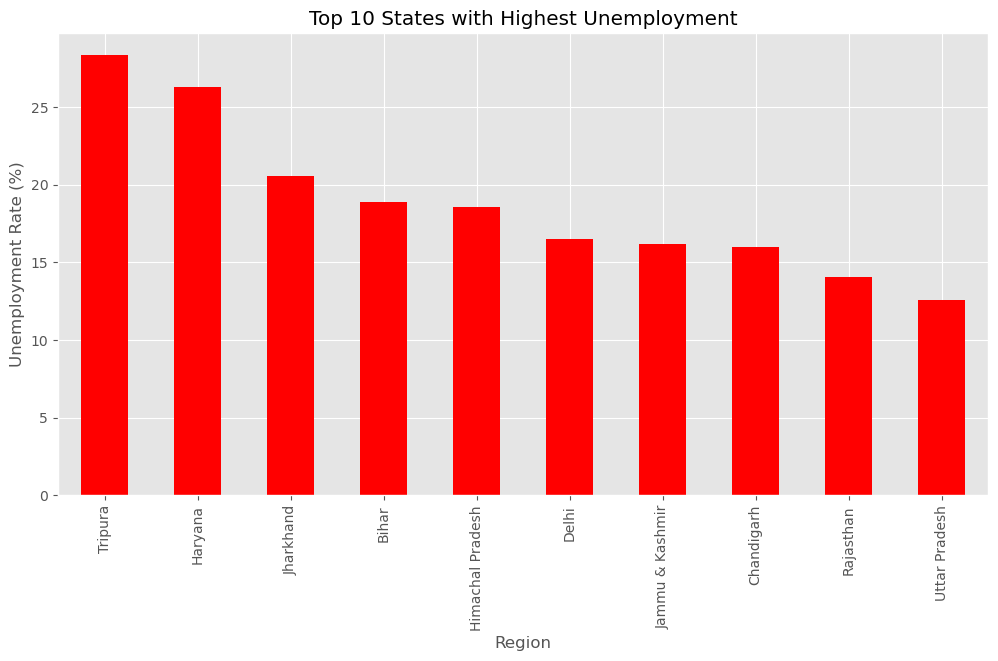

In [22]:
plt.figure(figsize=(12,6))

state_unemployment.head(10).plot(
    kind='bar',
    color='red'
)

plt.title("Top 10 States with Highest Unemployment")
plt.ylabel("Unemployment Rate (%)")

plt.savefig(
    "images/highest_unemployment_states.png"
)

plt.show()

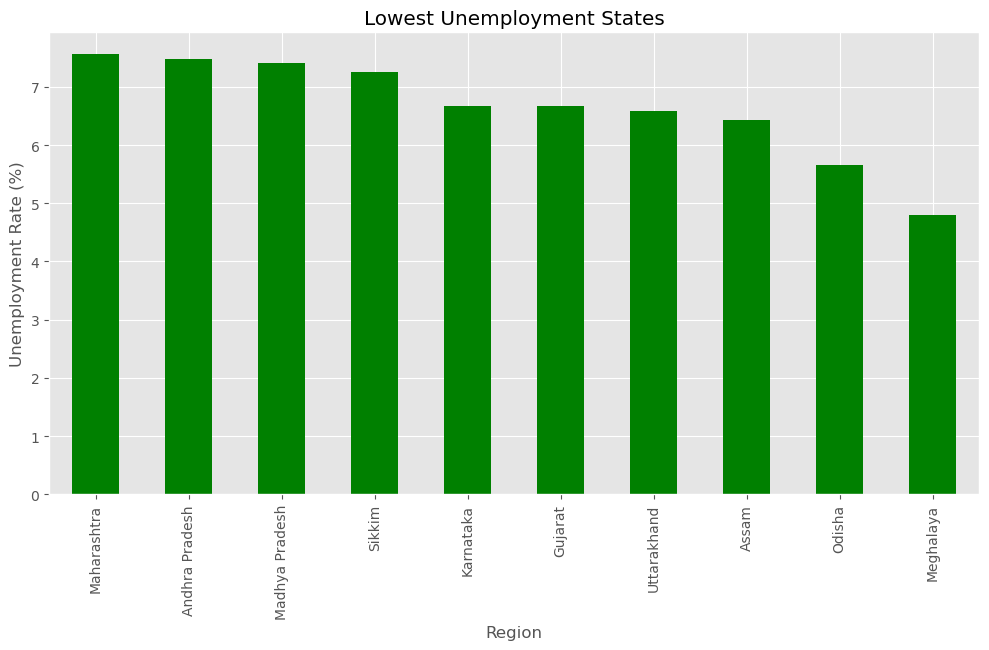

In [23]:
plt.figure(figsize=(12,6))

state_unemployment.tail(10).plot(
    kind='bar',
    color='green'
)

plt.title("Lowest Unemployment States")
plt.ylabel("Unemployment Rate (%)")

plt.savefig(
    "images/lowest_unemployment_states.png"
)

plt.show()

In [24]:
monthly_trend = df.groupby(
    df['Date'].dt.month
)['Estimated Unemployment Rate (%)'].mean()

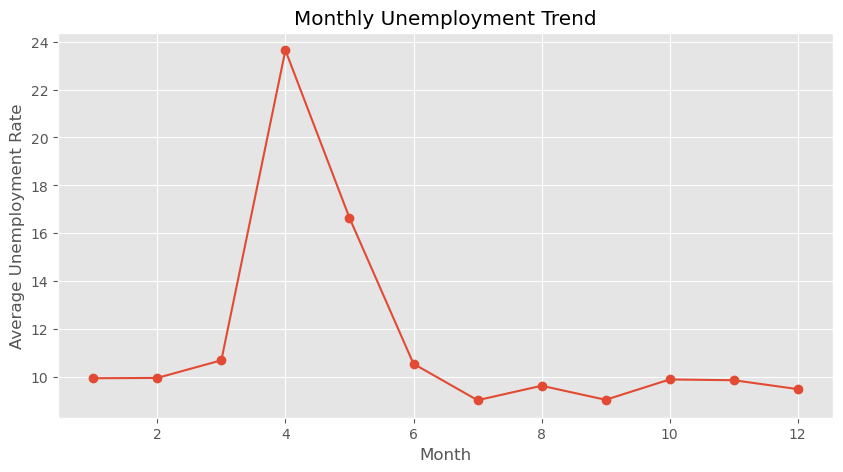

In [25]:
plt.figure(figsize=(10,5))

monthly_trend.plot(
    marker='o'
)

plt.title("Monthly Unemployment Trend")
plt.xlabel("Month")
plt.ylabel("Average Unemployment Rate")

plt.savefig(
    "images/monthly_trend.png"
)

plt.show()

In [26]:
df['Year'] = df['Date'].dt.year

In [27]:
covid = df.groupby(
    'Year'
)['Estimated Unemployment Rate (%)'].mean()

print(covid)

Year
2019     9.399047
2020    15.101581
Name: Estimated Unemployment Rate (%), dtype: float64


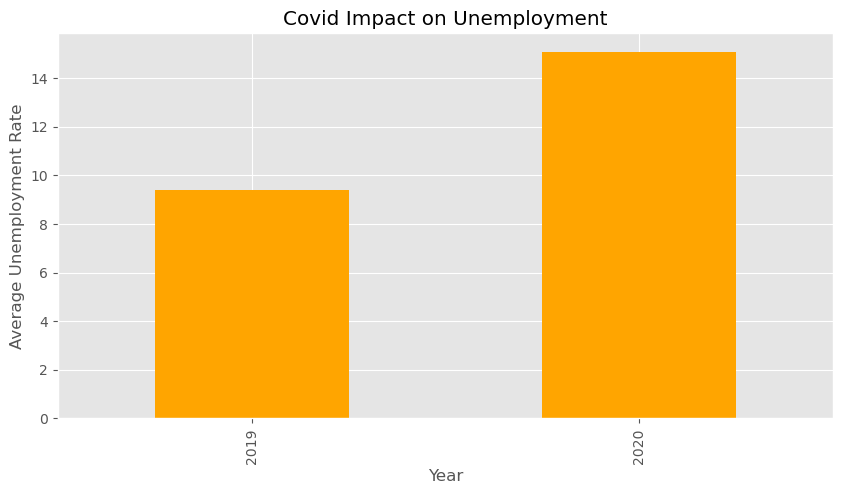

In [28]:
plt.figure(figsize=(10,5))

covid.plot(
    kind='bar',
    color='orange'
)

plt.title("Covid Impact on Unemployment")
plt.ylabel("Average Unemployment Rate")

plt.savefig(
    "images/covid_impact.png"
)

plt.show()

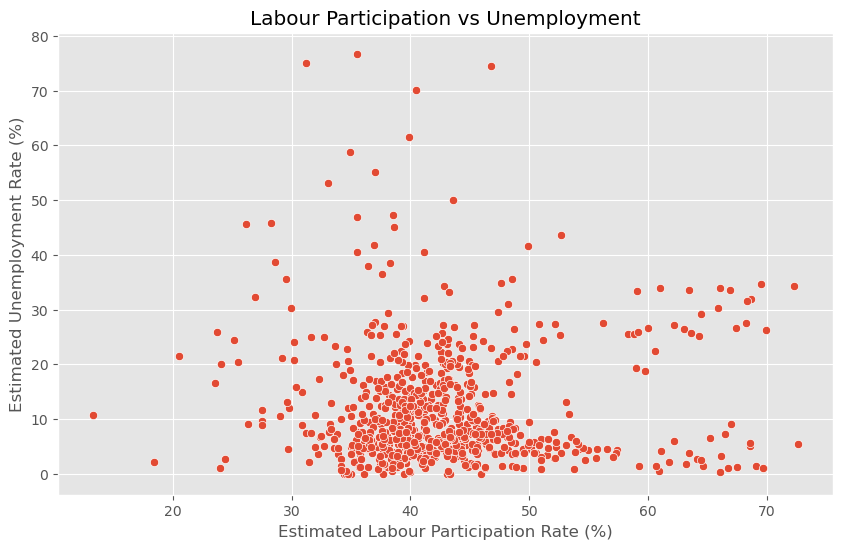

In [29]:
plt.figure(figsize=(10,6))

sns.scatterplot(
    x='Estimated Labour Participation Rate (%)',
    y='Estimated Unemployment Rate (%)',
    data=df
)

plt.title(
    "Labour Participation vs Unemployment"
)

plt.savefig(
    "images/labour_vs_unemployment.png"
)

plt.show()

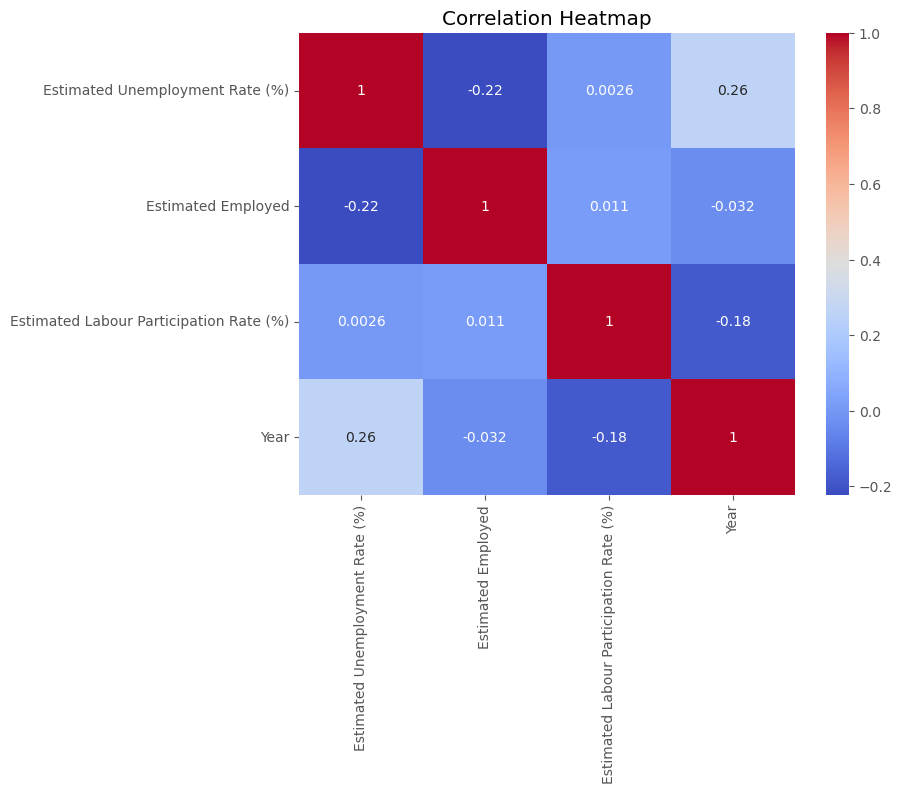

In [30]:
numeric_df = df.select_dtypes(include='number')

plt.figure(figsize=(8,6))

sns.heatmap(
    numeric_df.corr(),
    annot=True,
    cmap='coolwarm'
)

plt.title("Correlation Heatmap")

plt.savefig(
    "images/correlation_heatmap.png"
)

plt.show()

# Key Insights

1. Unemployment rates vary significantly across different states.

2. Certain states consistently exhibit higher unemployment rates.

3. The Covid-19 period saw a noticeable increase in unemployment.

4. Labour participation rate shows a relationship with unemployment trends.

5. Monthly unemployment rates reveal fluctuations indicating seasonal patterns.

6. Understanding these trends can help policymakers design employment generation programs.